In [1]:
!pip install -q tensorflow matplotlib scikit-learn pillow

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
from google.colab import files

print("TensorFlow version:", tf.__version__)
print("Setup completed successfully!")

TensorFlow version: 2.21.0
Setup completed successfully!


In [4]:
!wget -q -O asl_alphabet.zip \
https://storage.googleapis.com/kaggle-data-sets/005e

print("Download command completed.")

Download command completed.


In [6]:
!git clone -q https://github.com/ardamavi/Sign-Language-Digits-Dataset.git

fatal: destination path 'Sign-Language-Digits-Dataset' already exists and is not an empty directory.


In [7]:
import os
import numpy as np
from PIL import Image

DATASET_PATH = "/content/Sign-Language-Digits-Dataset/Dataset"
IMG_SIZE = 64

X = []
y = []

for label in range(10):
    folder = os.path.join(DATASET_PATH, str(label))

    for filename in os.listdir(folder):
        filepath = os.path.join(folder, filename)

        try:
            img = Image.open(filepath).convert("RGB")
            img = img.resize((IMG_SIZE, IMG_SIZE))
            X.append(np.array(img))
            y.append(label)
        except Exception:
            pass

X = np.array(X, dtype=np.uint8)
y = np.array(y, dtype=np.int64)

print("Images:", len(X))
print("Image shape:", X.shape)
print("Classes:", np.unique(y))

Images: 2062
Image shape: (2062, 64, 64, 3)
Classes: [0 1 2 3 4 5 6 7 8 9]


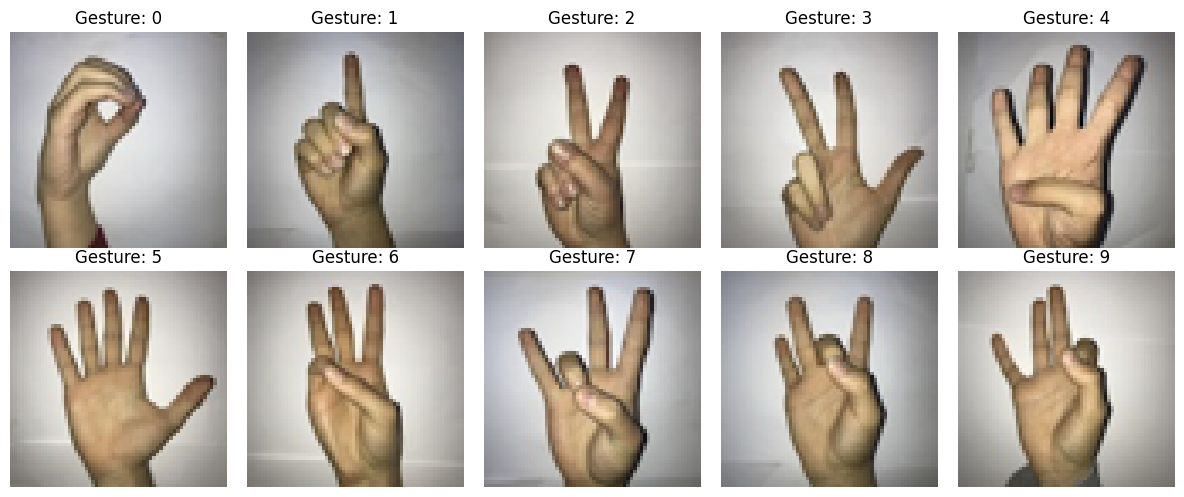

In [8]:
plt.figure(figsize=(12, 5))

for digit in range(10):
    indices = np.where(y == digit)[0]
    index = indices[0]

    plt.subplot(2, 5, digit + 1)
    plt.imshow(X[index])
    plt.title(f"Gesture: {digit}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
from sklearn.model_selection import train_test_split

# Normalize image pixels from 0-255 to 0-1
X = X.astype("float32") / 255.0

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print("Number of classes:", len(np.unique(y)))

Training images: 1649
Testing images: 413
Number of classes: 10


In [11]:
model = models.Sequential([
    layers.Input(shape=(64, 64, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,490 (2.61 MB)

 Trainable params: 684,490 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.15,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 16s 174ms/step - accuracy: 0.0871 - loss: 2.3036 - val_accuracy: 0.0685 - val_loss: 2.3032
Epoch 2/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.1035 - loss: 2.3027 - val_accuracy: 0.0685 - val_loss: 2.3040
Epoch 3/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1056 - loss: 2.3025 - val_accuracy: 0.0685 - val_loss: 2.3041
Epoch 4/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1064 - loss: 2.3024 - val_accuracy: 0.0685 - val_loss: 2.3043


In [13]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 9.93%
Test Loss: 2.3026


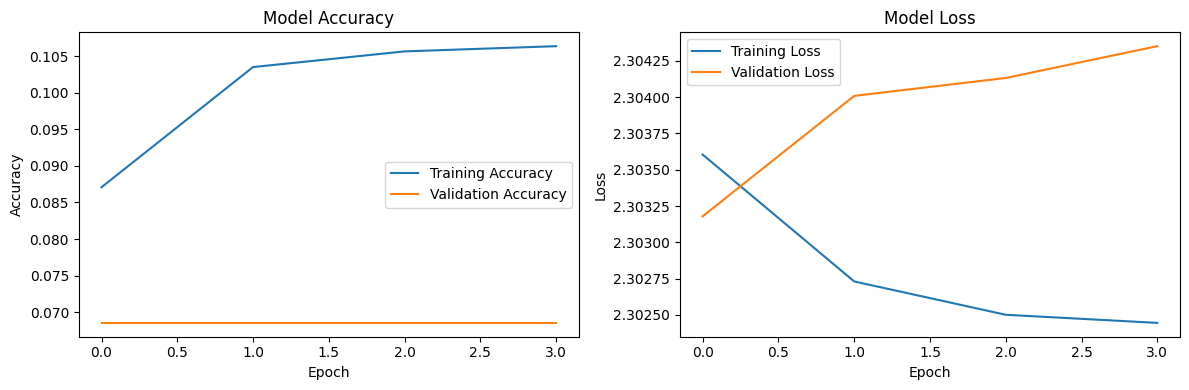

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


              precision    recall  f1-score   support

           0      0.000     0.000     0.000        41
           1      0.099     1.000     0.181        41
           2      0.000     0.000     0.000        41
           3      0.000     0.000     0.000        41
           4      0.000     0.000     0.000        41
           5      0.000     0.000     0.000        42
           6      0.000     0.000     0.000        42
           7      0.000     0.000     0.000        41
           8      0.000     0.000     0.000        42
           9      0.000     0.000     0.000        41

    accuracy                          0.099       413
   macro avg      0.010     0.100     0.018       413
weighted avg      0.010     0.099     0.018       413



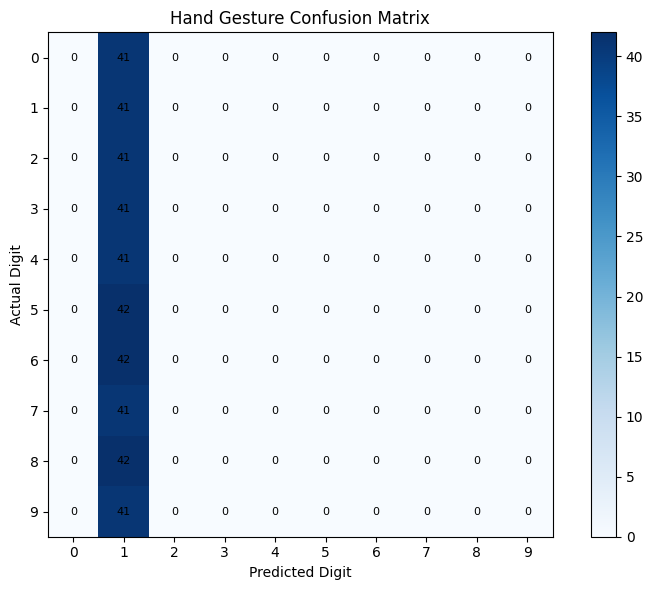

In [15]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

print(classification_report(y_test, y_pred, digits=3))

cm = confusion_matrix(y_test, y_pred, labels=list(range(10)))

plt.figure(figsize=(8, 6))
plt.imshow(cm, cmap="Blues")
plt.title("Hand Gesture Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.xticks(range(10))
plt.yticks(range(10))
plt.colorbar()

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.show()

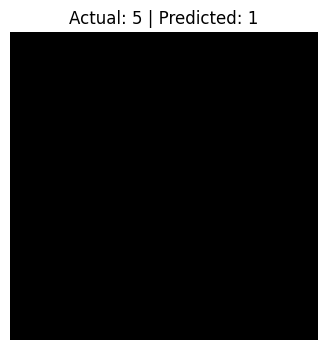

Actual gesture: 5
Predicted gesture: 1
Confidence: 10.07%


In [16]:
index = np.random.randint(0, len(X_test))

image = X_test[index]
actual = y_test[index]

prediction = model.predict(image[np.newaxis, ...], verbose=0)[0]
predicted = np.argmax(prediction)

plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.title(f"Actual: {actual} | Predicted: {predicted}")
plt.axis("off")
plt.show()

print("Actual gesture:", actual)
print("Predicted gesture:", predicted)
print(f"Confidence: {prediction[predicted] * 100:.2f}%")

Saving Screenshot 2026-10-13 211754.png to Screenshot 2026-10-13 211754.png


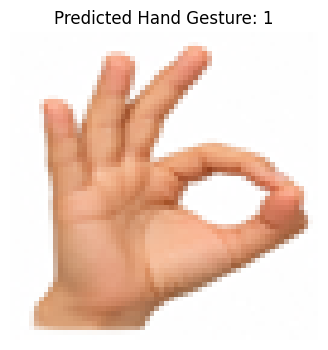

Predicted digit: 1
Confidence: 12.51%


In [17]:
from google.colab import files
from PIL import Image

uploaded = files.upload()

filename = next(iter(uploaded))

img = Image.open(filename).convert("RGB")
img = img.resize((64, 64))

image_array = np.array(img, dtype=np.float32) / 255.0

prediction = model.predict(
    image_array[np.newaxis, ...],
    verbose=0
)[0]

predicted_digit = int(np.argmax(prediction))

plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.title(f"Predicted Hand Gesture: {predicted_digit}")
plt.axis("off")
plt.show()

print("Predicted digit:", predicted_digit)
print(f"Confidence: {prediction[predicted_digit] * 100:.2f}%")

In [18]:
model.save("/content/hand_gesture_model.keras")

files.download("/content/hand_gesture_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np

# Define the generator model
def make_generator_model():
    model = tf.keras.Sequential([
        layers.Dense(8*8*256, use_bias=False, input_shape=(100,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Reshape((8, 8, 256)),

        layers.Conv2DTranspose(128, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64, (5, 5), strides=(2, 2), padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(3, (5, 5), strides=(2, 2), padding='same', use_bias=False, activation='tanh')
    ])
    return model

generator = make_generator_model()
generator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 16384)          │     1,638,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16384)          │        65,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 128)    │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 3)      │         4,800 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,733,504 (10.43 MB)

 Trainable params: 2,700,352 (10.30 MB)

 Non-trainable params: 33,152 (129.50 KB)

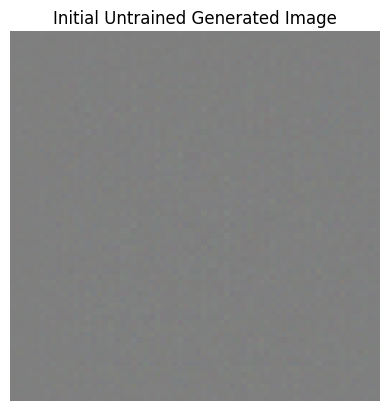

In [20]:
# Generate a sample random noise vector and plot the untrained generator's output
noise = tf.random.normal([1, 100])
generated_image = generator(noise, training=False)

plt.imshow((generated_image[0] + 1) / 2.0)
plt.title("Initial Untrained Generated Image")
plt.axis('off')
plt.show()

In [21]:
# Define the discriminator model
def make_discriminator_model():
    model = tf.keras.Sequential([
        layers.Input(shape=(64, 64, 3)),
        layers.Conv2D(64, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, (5, 5), strides=(2, 2), padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ])
    return model

discriminator = make_discriminator_model()

# Binary Cross Entropy Loss
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

generator_optimizer = tf.keras.optimizers.Adam(1e-4)
discriminator_optimizer = tf.keras.optimizers.Adam(1e-4)

print("Discriminator setup successfully!")

Discriminator setup successfully!


In [22]:
EPOCHS = 10
BATCH_SIZE = 64
noise_dim = 100

# Prepare dataset for GAN (scale to [-1, 1] to match generator tanh output)
X_gan = (X * 2.0) - 1.0
train_dataset = tf.data.Dataset.from_tensor_slices(X_gan).shuffle(len(X_gan)).batch(BATCH_SIZE)

@tf.function
def train_step(images):
    noise = tf.random.normal([BATCH_SIZE, noise_dim])

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated_images = generator(noise, training=True)

        real_output = discriminator(images, training=True)
        fake_output = discriminator(generated_images, training=True)

        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

    gradients_of_generator = gen_tape.gradient(gen_loss, generator.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    generator_optimizer.apply_gradients(zip(gradients_of_generator, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(gradients_of_discriminator, discriminator.trainable_variables))

def train(dataset, epochs):
    for epoch in range(epochs):
        for image_batch in dataset:
            if image_batch.shape[0] == BATCH_SIZE:
                train_step(image_batch)
        print(f"Epoch {epoch+1}/{epochs} completed.")

print("Training training pipeline...")
train(train_dataset, EPOCHS)

Training training pipeline...
Epoch 1/10 completed.
Epoch 2/10 completed.
Epoch 3/10 completed.
Epoch 4/10 completed.
Epoch 5/10 completed.
Epoch 6/10 completed.
Epoch 7/10 completed.
Epoch 8/10 completed.
Epoch 9/10 completed.
Epoch 10/10 completed.


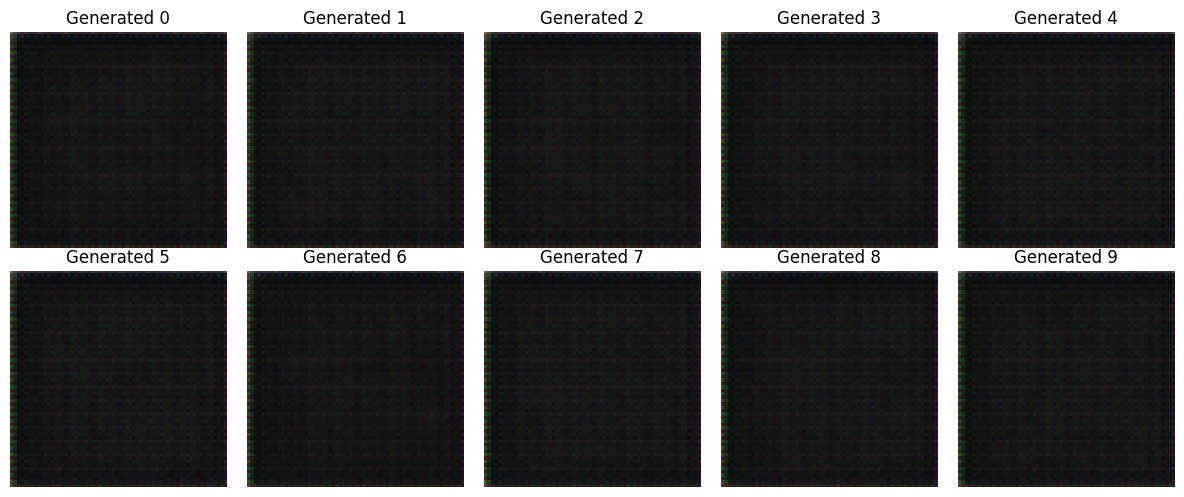

In [23]:
# Generate final hand gesture images after GAN training
noise = tf.random.normal([10, 100])
generated_images = generator(noise, training=False)

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i+1)
    # Rescale image from [-1, 1] to [0, 1] for visualization
    plt.imshow((generated_images[i] + 1) / 2.0)
    plt.title(f"Generated {i}")
    plt.axis('off')
plt.tight_layout()
plt.show()